In [1]:
from pca_utils import *

# Import data

In [2]:
path1 = "/mnt/c/users/helen/Desktop/190226/WT/foci2/aggregated_data.csv"
path2 = "/mnt/c/users/helen/Desktop/190226/MGS3/foci2/aggregated_data.csv"

In [3]:
df1 = pd.read_csv(path1)
df2 = pd.read_csv(path2)

In [4]:
df1["sample"] = "WT"
df2["sample"] = "MGS3"

combined_df = pd.concat(
    [df1, df2],
    ignore_index=True
)

In [5]:
# Clean data
combined_df.columns = combined_df.columns.str.strip().str.lower()
combined_df.iloc[:, 1:10] = combined_df.iloc[:, 1:10].apply(pd.to_numeric, errors="coerce")
df = combined_df.dropna()

print("Number of cells is:", df.shape[0])

Number of cells is: 59


In [6]:
combined_df.tail()

,image_id,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,sample
54,C2_MP_U2OS_fixed_MGS3_002.nd2_(series_19)_ROI_...,291,3.0,1.954410,1.000000,1.000000,2.000000,29.000000,32.0,25.0,MGS3
55,C2_MP_U2OS_fixed_MGS3_002.nd2_(series_20)_ROI_...,259,3.0,1.954410,1.000000,1.000000,1.000000,31.750000,35.0,29.0,MGS3
56,C2_MP_U2OS_fixed_MGS3_002.nd2_(series_21)_ROI_...,295,3.0,1.954410,0.958691,1.000000,3.207107,35.043480,38.0,32.0,MGS3
57,C2_MP_U2OS_fixed_MGS3_002.nd2_(series_22)_ROI_...,107,6.0,2.763953,0.899735,0.875000,6.207107,74.333336,84.0,65.0,MGS3
58,C2_MP_U2OS_fixed_MGS3_002.nd2_(series_23)_ROI_...,145,4.0,2.256758,0.912871,0.970588,4.000000,59.490566,66.0,53.0,MGS3


# Correlation analysis

In [7]:
# Select numerical columns
df_numeric = df.select_dtypes(include=np.number)

# Calculate Spearman correlation
corr = df_numeric.corr(method="spearman")

display(corr.round(3))

,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity
n_foci,1.000,-0.589,-0.589,0.551,0.543,-0.512,-0.570,-0.583,-0.556
area,-0.589,1.000,1.000,-0.759,-0.706,0.806,0.555,0.565,0.528
equivalent_diameter_area,-0.589,1.000,1.000,-0.759,-0.706,0.806,0.555,0.565,0.528
eccentricity,0.551,-0.759,-0.759,1.000,0.561,-0.953,-0.678,-0.674,-0.640
solidity,0.543,-0.706,-0.706,0.561,1.000,-0.582,-0.482,-0.490,-0.467
perimeter,-0.512,0.806,0.806,-0.953,-0.582,1.000,0.673,0.672,0.634
mean_intensity,-0.570,0.555,0.555,-0.678,-0.482,0.673,1.000,0.998,0.995
max_intensity,-0.583,0.565,0.565,-0.674,-0.490,0.672,0.998,1.000,0.993
min_intensity,-0.556,0.528,0.528,-0.640,-0.467,0.634,0.995,0.993,1.000


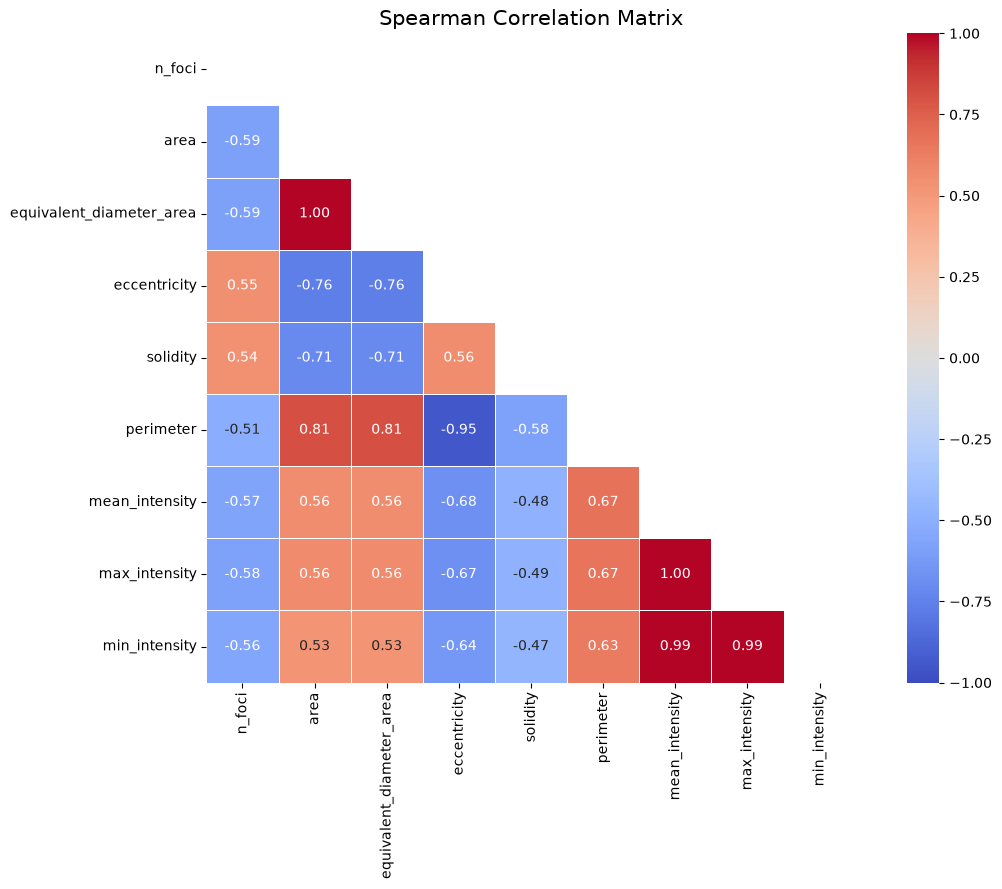

In [8]:
plt.figure(figsize=(12, 9))

# Show only lower triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Spearman Correlation Matrix", fontsize=15)
plt.tight_layout()
plt.show()

## Graphs

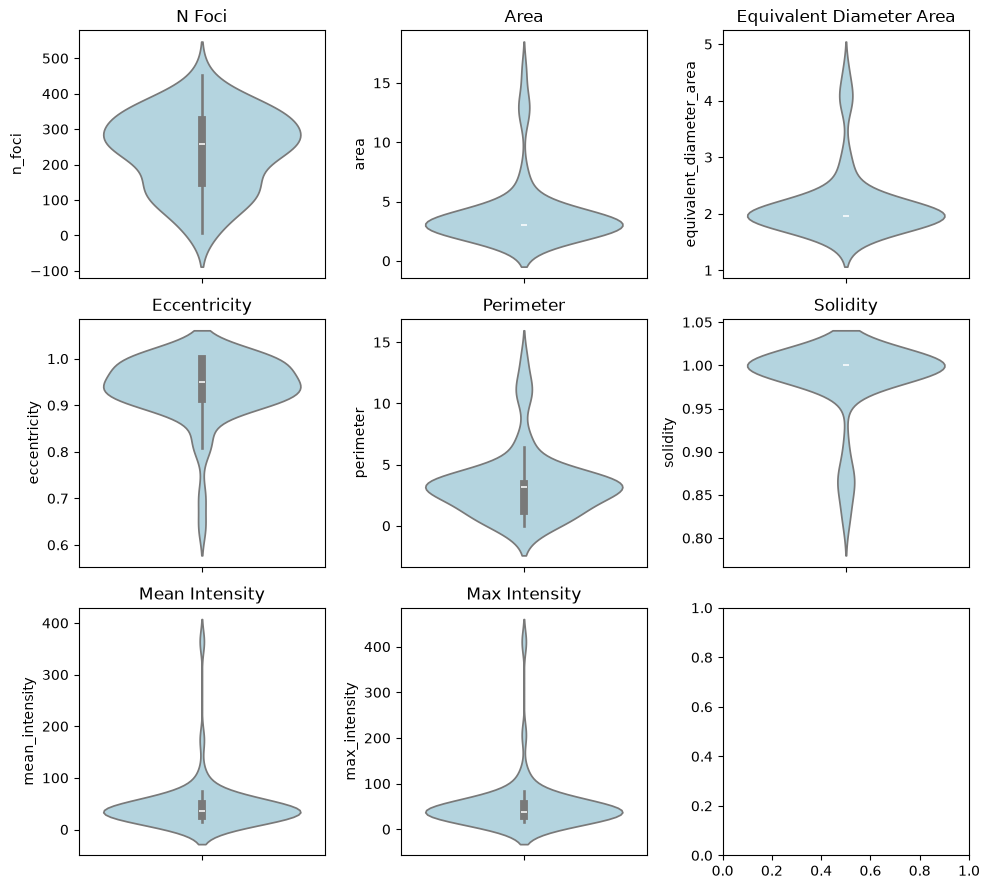

In [9]:
features = [
    "n_foci",
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
]

fig, axes = plt.subplots(3, 3, figsize=(10, 9))

for ax, feature in zip(axes.flat, features):

    sns.violinplot(
        data=df,
        y=feature,
        color="lightblue",
        inner="box",
        legend=False,
        ax=ax
    )
    
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()


# PCA

In [10]:
# Features
features = [
    "n_foci",
    #"area",
    "equivalent_diameter_area",
    #"eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
]

# Select features and scale them
pca_df = df.copy()

X = df[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

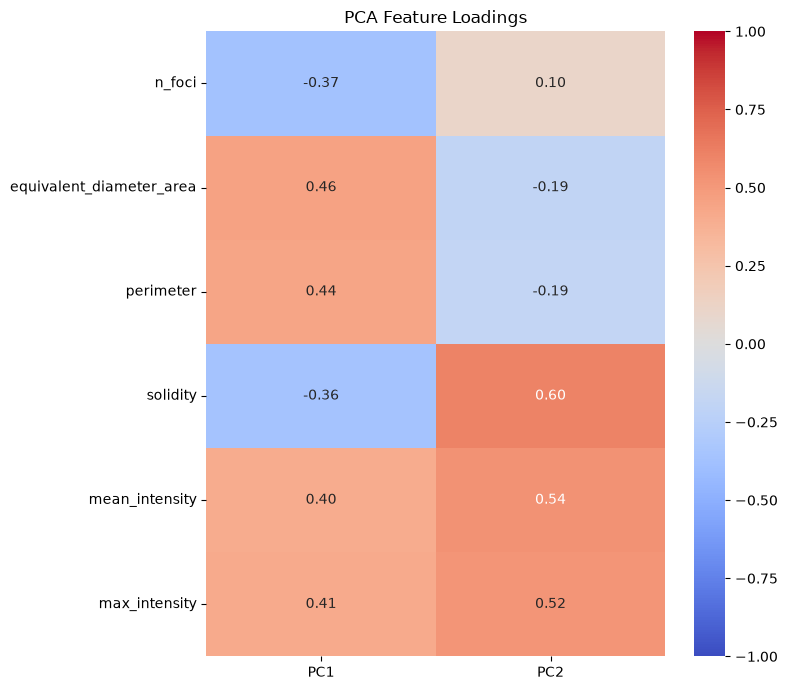

In [11]:
# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=['PC1', 'PC2']
)

#display(loadings.round(3))

# Heatmap of PCA loadings
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

In [13]:
centroids = pca_df.groupby("sample")[["PC1", "PC2"]].mean()

print(centroids)

             PC1       PC2
sample                    
MGS3    0.646295  0.238772
WT     -0.443174 -0.163729


In [ ]:
#centroids = plot_pca_centroids_ci(
    #pca_df,
    #group_col="sample",
    #confidence=0.95
#)

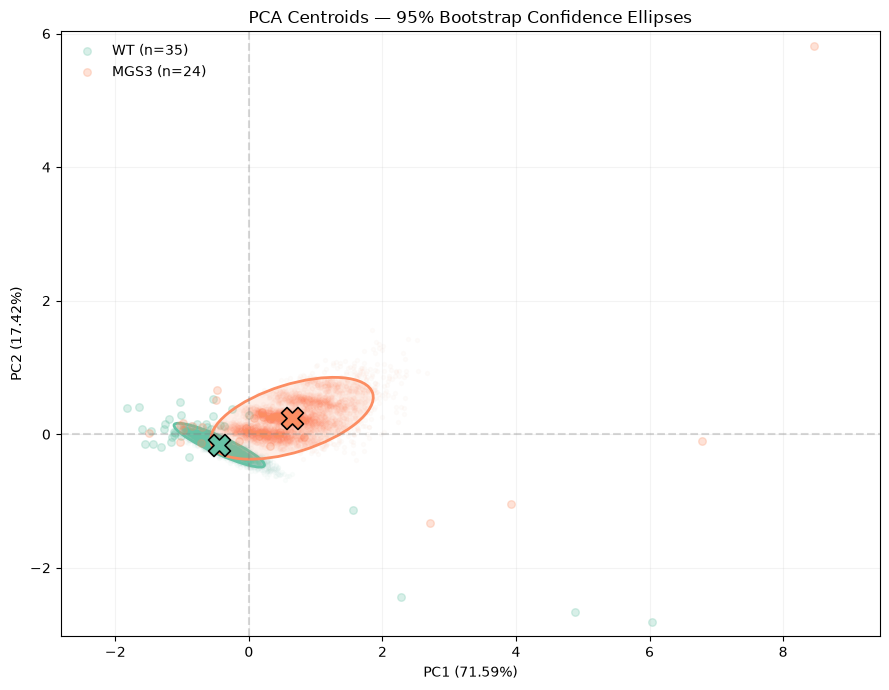

In [15]:
results_boot = bootstrap_pca_centroids(
    pca_df,
    group_col="sample",
    n_boot=5000,
    confidence=0.95,
    pca = pca
)

In [16]:
results_stats = pca_permanova(
    pca_df,
    group_col="sample"
)

results_stats

,Test,Statistic,p_value,R2,n,groups
0,PERMANOVA,3.699936,0.0314,0.060955,59,2
1,PERMDISP,1.061978,0.3179,NaN,59,2


# Detect outliers

In [17]:
from scipy.spatial.distance import mahalanobis
from scipy.stats import chi2

def detect_pca_outliers(
    df,
    group_col="sample",
    features=("PC1", "PC2"),
    confidence=0.99
):
    result = df.copy()

    result["mahalanobis_distance"] = np.nan
    result["outlier"] = False

    threshold = chi2.ppf(confidence, df=len(features))

    for group, group_df in result.groupby(group_col):

        X = group_df[list(features)].dropna()

        if len(X) <= len(features):
            continue

        # Group centroid
        centroid = X.mean(axis=0).values

        # Covariance matrix
        cov = np.cov(X.values, rowvar=False)

        # Inverse covariance
        inv_cov = np.linalg.pinv(cov)

        # Mahalanobis distances
        distances = np.array([
            mahalanobis(row, centroid, inv_cov)
            for row in X.values
        ])

        result.loc[X.index, "mahalanobis_distance"] = distances

        result.loc[X.index, "outlier"] = (
            distances**2 > threshold
        )

    return result

In [18]:
pca_df_outliers = detect_pca_outliers(
    pca_df,
    group_col="sample",
    features=("PC1", "PC2"),
    confidence=0.99
)

# Display detected outliers
outliers = pca_df_outliers[
    pca_df_outliers["outlier"]
]

display(outliers)

,image_id,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,sample,PC1,PC2,mahalanobis_distance,outlier
4,C2_MP_U2OS_fixed_WT_001.nd2_(series_11)_ROI_02...,49,6.0,2.763953,0.836390,0.868421,6.414214,30.000000,35.0,25.0,WT,2.277740,-2.436540,3.460404,True
16,C2_MP_U2OS_fixed_WT_001.nd2_(series_25)_ROI_02...,83,13.0,4.068429,0.816497,0.835616,11.035534,71.000000,84.0,61.0,WT,4.881173,-2.668308,3.191828,True
18,C2_MP_U2OS_fixed_WT_001.nd2_(series_27)_ROI_02...,84,16.0,4.513517,0.807260,0.820561,13.553301,86.973682,105.5,73.0,WT,6.042908,-2.807591,3.895174,True
40,C2_MP_U2OS_fixed_MGS3_002.nd2_(series_03)_ROI_...,8,13.5,4.139507,0.703547,0.867406,11.571068,173.663040,207.0,146.5,MGS3,6.783855,-0.099991,3.059632,True
42,C2_MP_U2OS_fixed_MGS3_002.nd2_(series_05)_ROI_...,7,12.0,3.908820,0.638488,1.000000,10.485281,364.285706,411.0,319.0,MGS3,8.455840,5.811912,4.553677,True


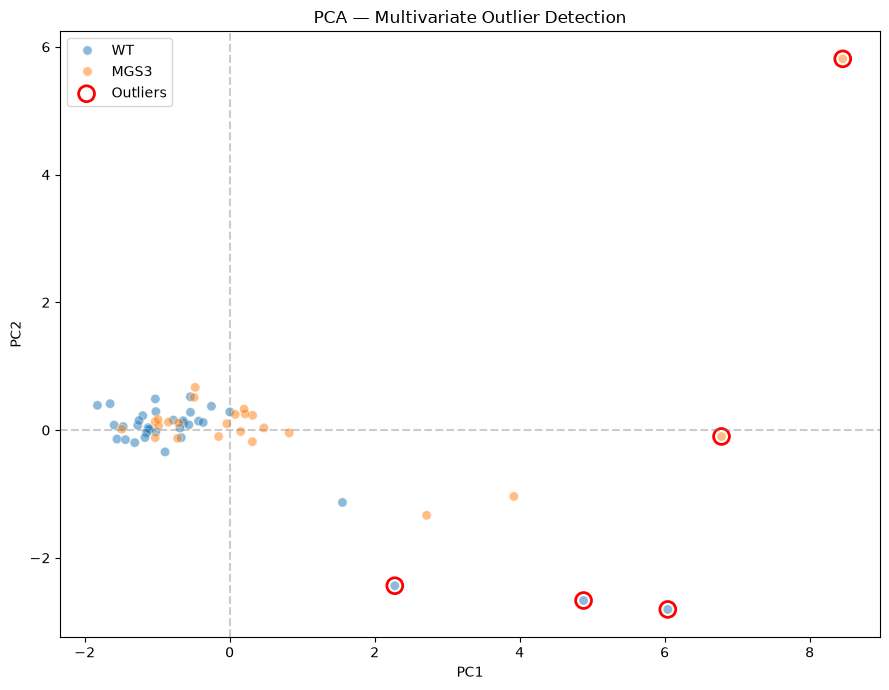

In [19]:
fig, ax = plt.subplots(figsize=(9, 7))

sns.scatterplot(
    data=pca_df_outliers,
    x="PC1",
    y="PC2",
    hue="sample",
    alpha=0.5,
    s=45,
    ax=ax
)

# Highlight outliers
outliers = pca_df_outliers[pca_df_outliers["outlier"]]

ax.scatter(
    outliers["PC1"],
    outliers["PC2"],
    s=130,
    facecolors="none",
    edgecolors="red",
    linewidths=2,
    label="Outliers"
)

ax.axhline(0, color="gray", linestyle="--", alpha=0.4)
ax.axvline(0, color="gray", linestyle="--", alpha=0.4)

ax.set_title("PCA — Multivariate Outlier Detection")
ax.legend()
plt.tight_layout()
plt.show()

In [29]:
df_clean = df.loc[~df.index.isin(outliers.index)].copy()
df_clean.shape

(54, 11)

In [31]:
# Features
features = [
    "n_foci",
    #"area",
    "equivalent_diameter_area",
    #"eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
]

# Select features and scale them
pca_df = df_clean.copy()

X = df_clean[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

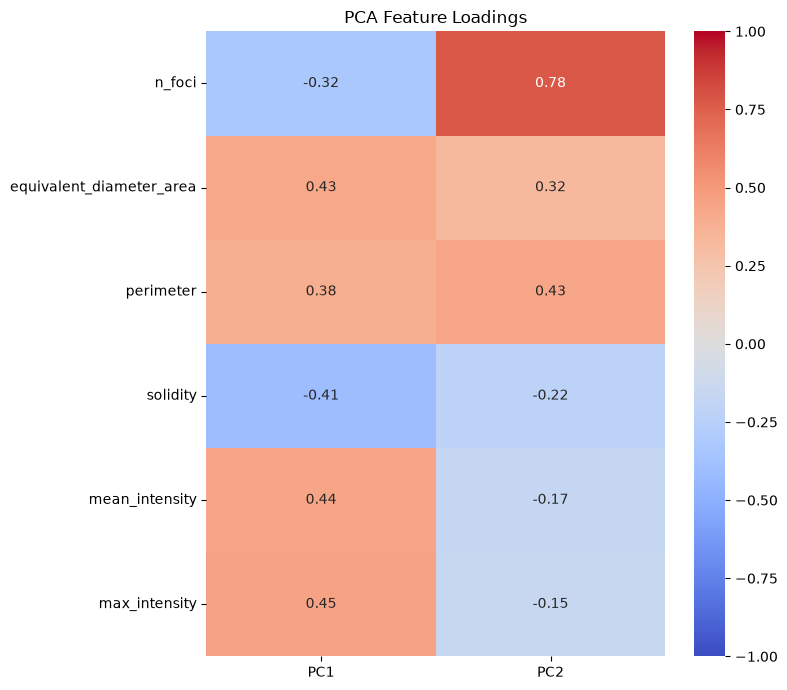

In [32]:
# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=['PC1', 'PC2']
)

#display(loadings.round(3))

# Heatmap of PCA loadings
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

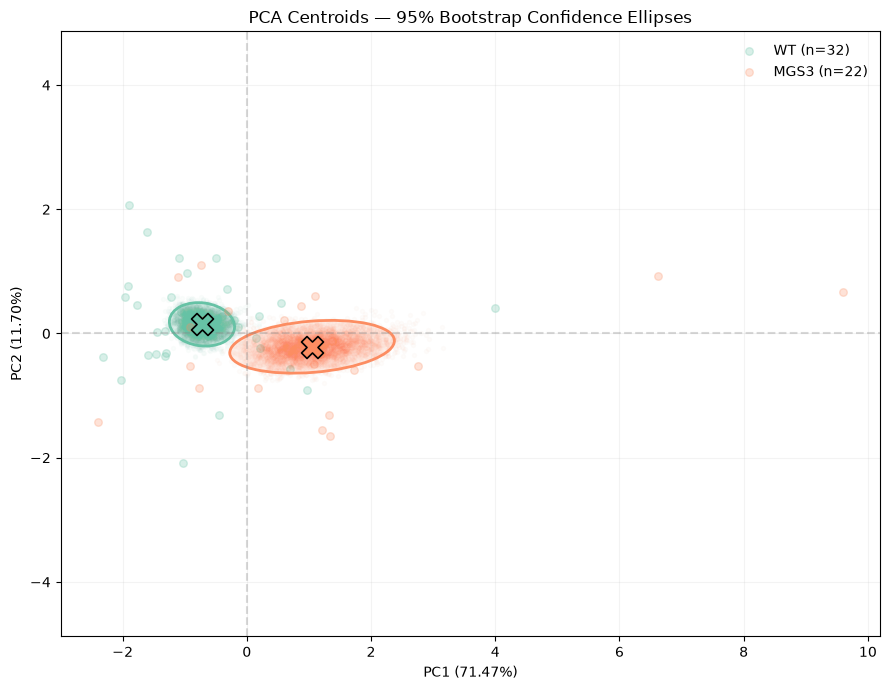

In [33]:
results_boot = bootstrap_pca_centroids(
    pca_df,
    group_col="sample",
    n_boot=5000,
    confidence=0.95,
    pca = pca
)

In [34]:
results_stats = pca_permanova(
    pca_df,
    group_col="sample"
)

results_stats

,Test,Statistic,p_value,R2,n,groups
0,PERMANOVA,9.788501,0.0004,0.158419,54,2
1,PERMDISP,3.265693,0.0705,NaN,54,2
